## 📓 Notebook 02: Preprocess & Split

**Skills practiced:** Per-column missing-value handling, encoding categoricals, `train_test_split(stratify=)`, fitting `StandardScaler` on train only.

**Goal:** Build one shared, encoded, scaled, stratified train/test split and save it to `data/processed/` for every later notebook to reuse.


In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

df=pd.read_csv('../data/processed/loans_cleaned.csv')

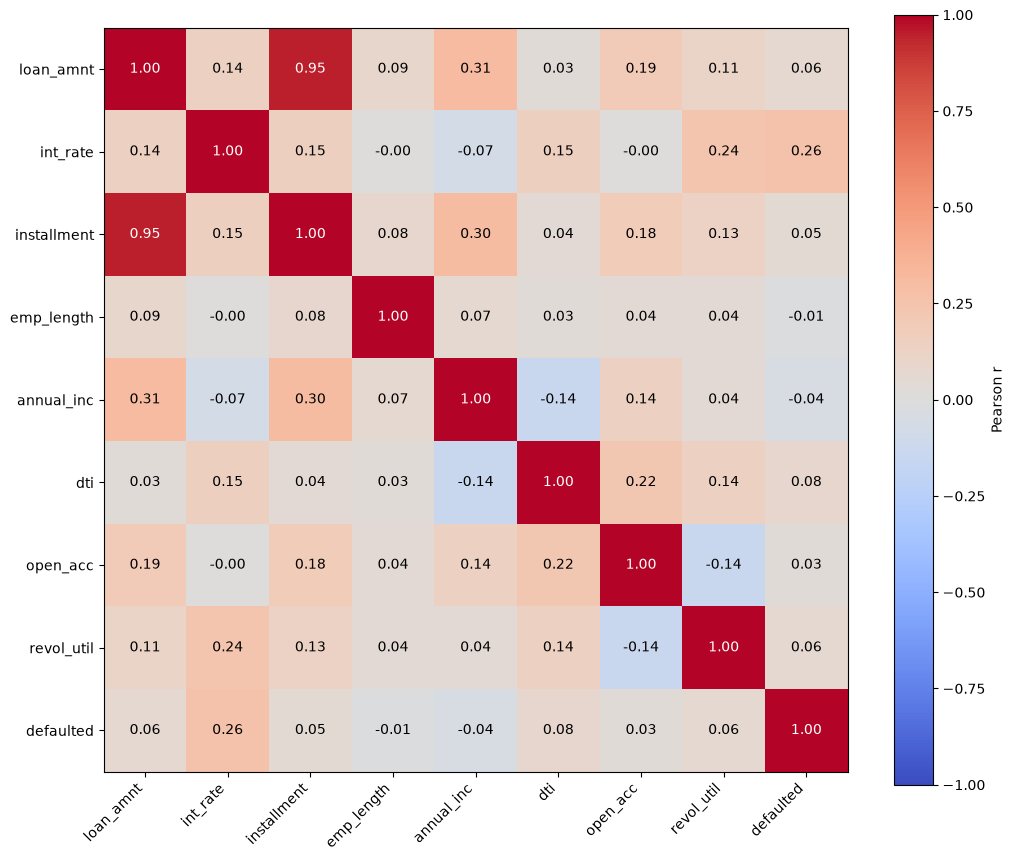

In [9]:
import numpy as np
import matplotlib.pyplot as plt
corr=df.select_dtypes(include=[np.number]).corr().round(2)
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, label="Pearson r")
plt.show()

In [10]:


order = {
    "< 1 year": 0, "1 year": 1, "2 years": 2, "3 years": 3, "4 years": 4,
    "5 years": 5, "6 years": 6, "7 years": 7, "8 years": 8, "9 years": 9,
    "10+ years": 10,
}

df["emp_length"] = df["emp_length"].map(order)

text_cols =df.select_dtypes(include=["object", "str"]).columns.tolist()
print(text_cols)

['emp_title', 'home_ownership', 'loan_status', 'purpose']


In [11]:
df['purpose'] = df["purpose"].str.lower().str.strip()

counts = df["purpose"].value_counts()
keep = counts[counts >= 100].index

df = df[df["purpose"].isin(keep)]
print(df["purpose"].nunique(), len(df))


147 1238740


In [12]:
print(df['defaulted'].value_counts(normalize=True))

defaulted
0    0.797797
1    0.202203
Name: proportion, dtype: float64


In [13]:
ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore", drop=None)     # unseen categories -> all zeros
enc = pd.DataFrame(ohe.fit_transform(df[["home_ownership","purpose"]]), columns=ohe.get_feature_names_out())
df = pd.concat([df.drop(columns=["home_ownership","purpose"]), enc], axis=1)
df.info()

<class 'pandas.DataFrame'>
Index: 1345423 entries, 0 to 1238739
Columns: 164 entries, loan_amnt to purpose_wedding loan
dtypes: float64(162), str(2)
memory usage: 1.7 GB


In [14]:
df=df.dropna()  # drop rows with missing values
X=df.drop(columns=["loan_status","emp_title", "defaulted"])
Y=df["defaulted"].astype(int)

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, stratify=Y,           # stratify keeps class ratios equal (classification)
    random_state=42)

print(X_train.shape, X_test.shape, Y_train.mean().round(3), Y_test.mean().round(3))

ValueError: With n_samples=0, test_size=0.2 and train_size=None, the resulting train set will be empty. Adjust any of the aforementioned parameters.

In [ ]:
lo, hi = X_train["annual_inc"].quantile([0.001, 0.999])
X_train["annual_inc"] = X_train["annual_inc"].clip(lo, hi)
X_test["annual_inc"] = X_test["annual_inc"].clip(lo, hi)

In [ ]:
scaler = StandardScaler()
scaler.fit(X_train)

scaled_X_train = scaler.transform(X_train)
scaled_X_test = scaler.transform(X_test)

print(scaler.mean_[:4])  # mean of each feature in training set
print(scaler.scale_[:4])  # standard deviation of each feature in training set

[1.47267326e+04 1.31474192e+01 4.45719780e+02 5.98490662e+00]
[8.73455459e+03 4.74378971e+00 2.61438170e+02 3.69172611e+00]


In [ ]:
scaled_X_train = pd.DataFrame(scaled_X_train, columns=X_train.columns, index=X_train.index)
scaled_X_test = pd.DataFrame(scaled_X_test, columns=X_test.columns, index=X_test.index)
X_train = pd.DataFrame(X_train, columns=X_train.columns, index=X_train.index)
X_test = pd.DataFrame(X_test, columns=X_test.columns, index=X_test.index)
Y_train = pd.DataFrame(Y_train, columns=['defaulted'], index=Y_train.index)
Y_test = pd.DataFrame(Y_test, columns=['defaulted'], index=Y_test.index)

scaled_X_train.to_csv('../data/processed/X_train_scaled.csv', index=False)
scaled_X_test.to_csv('../data/processed/X_test_scaled.csv', index=False)
Y_train.to_csv('../data/processed/Y_train.csv', index=False)
Y_test.to_csv('../data/processed/Y_test.csv', index=False)
X_train.to_csv('../data/processed/X_train.csv', index=False)
X_test.to_csv('../data/processed/X_test.csv', index=False)


print(X_train.isna().sum().sum(), scaled_X_train.isna().sum().sum(), Y_train.isna().sum().sum())   # both 0

check_Scaled_X = pd.read_csv("../data/processed/X_train_scaled.csv")
check_X = pd.read_csv("../data/processed/X_train.csv")
check_Y = pd.read_csv("../data/processed/Y_train.csv")
print(check_X.shape, check_Scaled_X.shape, check_Y.shape)
print(len(check_X) == len(check_Scaled_X) == len(check_Y))  # True

KeyboardInterrupt: 